# Importing libraries and loading data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

rfm = pd.read_csv('rfm_segments.csv')
rfm.shape

(5878, 10)

# Customers vs Revenue share by segment

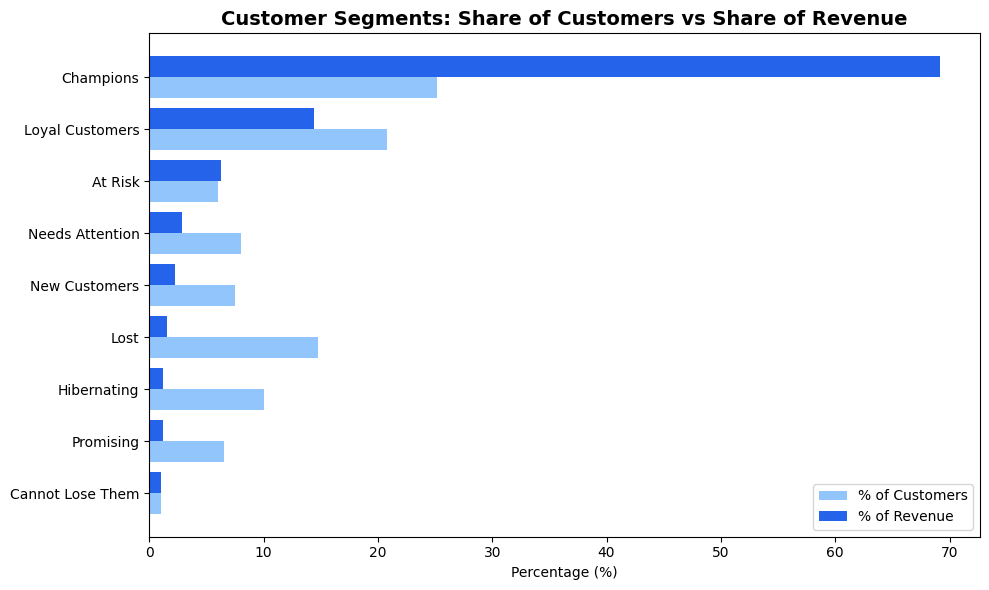

In [2]:
seg = rfm.groupby('Segment').agg(
    customers=('Customer ID', 'count'),
    revenue=('Monetary', 'sum')
).reset_index()
seg['pct_customers'] = seg['customers'] / seg['customers'].sum() * 100
seg['pct_revenue'] = seg['revenue'] / seg['revenue'].sum() * 100
seg = seg.sort_values('revenue', ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
y = range(len(seg))
ax.barh([i - 0.2 for i in y], seg['pct_customers'], height=0.4, label='% of Customers', color='#93c5fd')
ax.barh([i + 0.2 for i in y], seg['pct_revenue'], height=0.4, label='% of Revenue', color='#2563eb')
ax.set_yticks(list(y))
ax.set_yticklabels(seg['Segment'])
ax.set_xlabel('Percentage (%)')
ax.set_title('Customer Segments: Share of Customers vs Share of Revenue', fontsize=14, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('chart1_segment_revenue_share.png', dpi=150)
plt.show()

# Segment sizes, color-coded by health

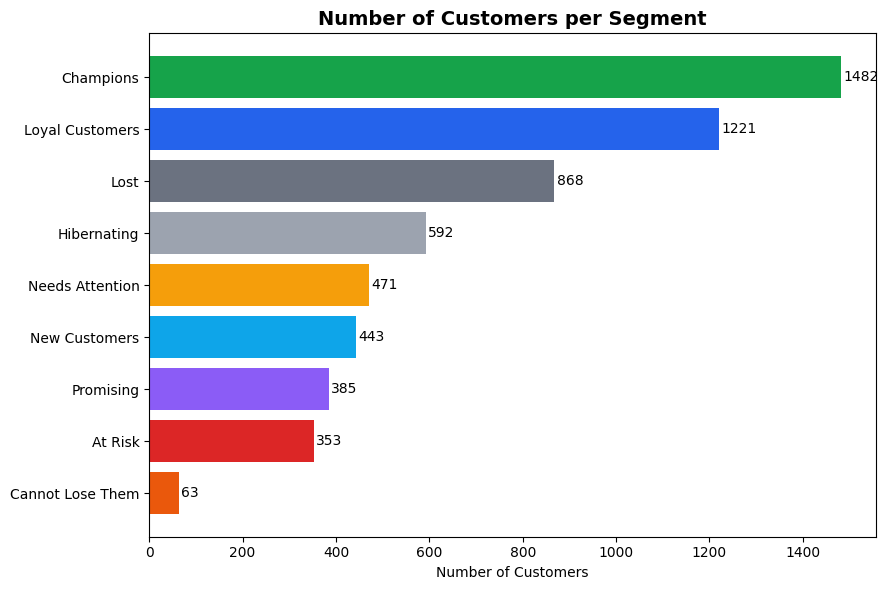

In [3]:
seg_count = rfm['Segment'].value_counts().sort_values()

colors_map = {
    'Champions': '#16a34a', 'Loyal Customers': '#2563eb', 'At Risk': '#dc2626',
    'Cannot Lose Them': '#ea580c', 'Needs Attention': '#f59e0b', 'New Customers': '#0ea5e9',
    'Lost': '#6b7280', 'Hibernating': '#9ca3af', 'Promising': '#8b5cf6'
}
bar_colors = [colors_map.get(s, '#2563eb') for s in seg_count.index]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(seg_count.index, seg_count.values, color=bar_colors)
ax.set_title('Number of Customers per Segment', fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Customers')
for i, v in enumerate(seg_count.values):
    ax.text(v + 5, i, str(v), va='center')
plt.tight_layout()
plt.savefig('chart2_segment_sizes.png', dpi=150)
plt.show()

# Recency vs Monetary scatter, colored by segment

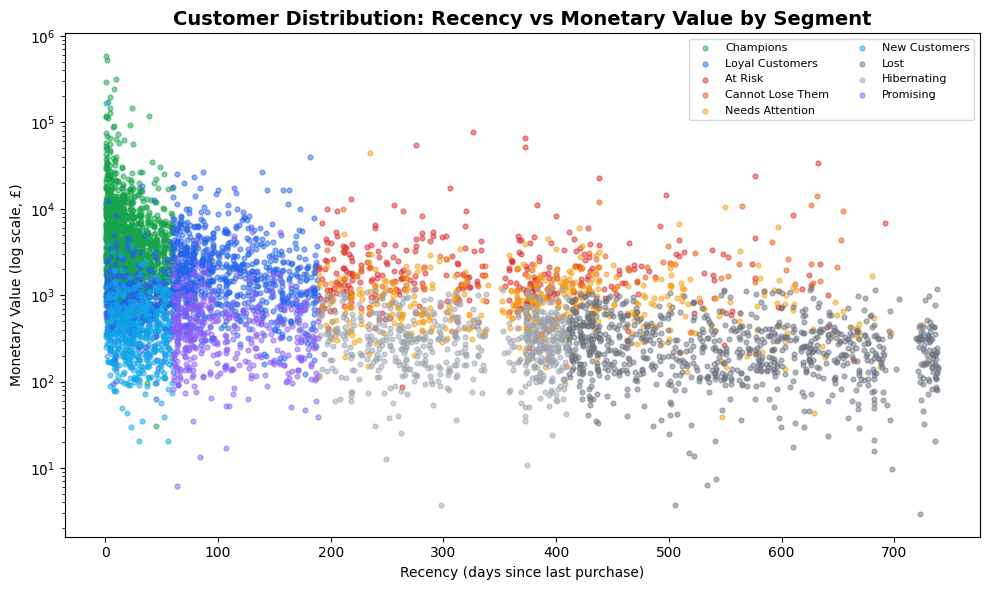

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
for seg_name, color in colors_map.items():
    subset = rfm[rfm['Segment'] == seg_name]
    ax.scatter(subset['Recency'], subset['Monetary'], s=12, alpha=0.5, label=seg_name, color=color)

ax.set_yscale('log')
ax.set_xlabel('Recency (days since last purchase)')
ax.set_ylabel('Monetary Value (log scale, £)')
ax.set_title('Customer Distribution: Recency vs Monetary Value by Segment', fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig('chart3_recency_vs_monetary.png', dpi=150)
plt.show()

# RFM heatmap

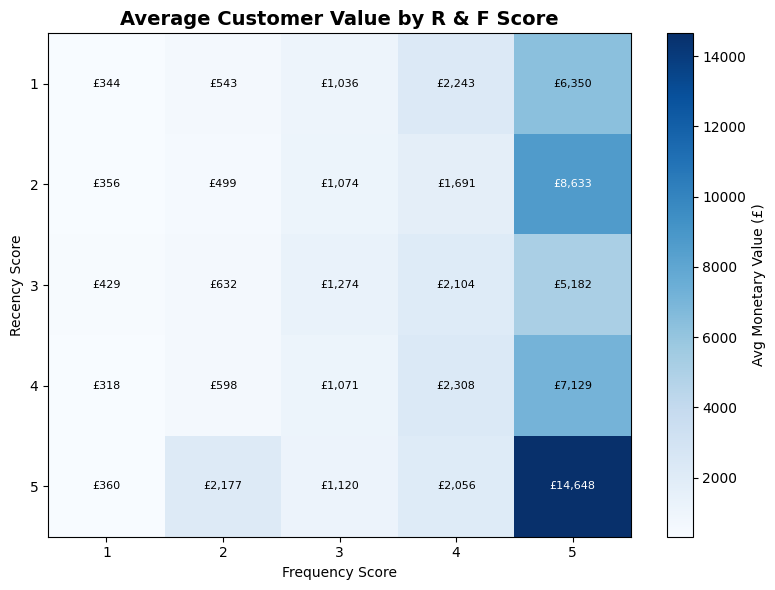

In [5]:
pivot = rfm.pivot_table(index='R_Score', columns='F_Score', values='Monetary', aggfunc='mean')

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(pivot, cmap='Blues', aspect='auto')
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_xlabel('Frequency Score')
ax.set_ylabel('Recency Score')
ax.set_title('Average Customer Value by R & F Score', fontsize=14, fontweight='bold')

for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        val = pivot.values[i, j]
        if not pd.isna(val):
            ax.text(j, i, f'£{val:,.0f}', ha='center', va='center', fontsize=8,
                     color='white' if val > pivot.values.max()*0.5 else 'black')

plt.colorbar(im, label='Avg Monetary Value (£)')
plt.tight_layout()
plt.savefig('chart4_rf_heatmap.png', dpi=150)
plt.show()